# Step 5 — Station distance, terrain, and the circularity test

Spec: `CLAUDE.md` §6 Step 5 (promoted 2026-09-23), §5.3a. **This step determines what the K2
result means.**

**Why.** §5.3a established from primary documentation that **PRISM ingests CIMIS** — its Table A1
lists CIMIS under `AN91d` for Tmax/Tmin, which is the product used here — and that **gridMET
inherits the dependency** by bias-correcting daily PRISM. **Daymet (GHCN-Daily), ERA5-Land and the
satellites do not ingest CIMIS.** So Step 4 scored two of the five products against the very
observations they were interpolated from, at those observations' own locations.

**The test.** If a grid's advantage is a fitting artefact, its error should grow with distance
from its own input stations while the satellite's stays flat — the satellite has no station
inputs, so it has no such distance. Extrapolated to the distances at which orchards actually sit,
that would mean *the grid wins where it was fitted, and the satellite may not lose where it was
not.*

**A limit to state up front.** Ground truth exists only at CIMIS stations, and **PRISM ingests
every one of them**. PRISM's error at a location it did not ingest is therefore **not measurable
with this data at all**. What can be measured is (a) how each product's error varies with distance
from the **GHCN-Daily** network, which Daymet interpolates from and which varies across our
stations, and (b) whether the satellite's error is flat with respect to both networks, as it must
be if it depends on neither.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import common as C

plt.rcParams["mathtext.default"] = "regular"
PRODS = [("VIIRS", "viirs_lst_c"), ("Daymet", "daymet"), ("PRISM", "prism"),
         ("gridMET", "gridmet"), ("ERA5-Land", "era5land")]
INGESTS = {"VIIRS": "none (satellite)", "Daymet": "GHCN-Daily", "PRISM": "CIMIS + others",
           "gridMET": "CIMIS + others, via PRISM", "ERA5-Land": "none (no assimilation)"}
MIN_NIGHTS = 20

m = pd.read_csv(C.DERIVED / "04_point_comparison.csv", parse_dates=["date"])
cov = pd.read_csv(C.DERIVED / "05_station_covariates.csv")
cov["station"] = cov.StationNbr.astype(int)
matched = m[(m.frost) & (m.viirs == True)].copy()
print(f"matched frost station-nights (Step 4 subset): {len(matched):,}")
print(f"stations: {matched.station.nunique()}")

matched frost station-nights (Step 4 subset): 2,532
stations: 59


In [2]:
def loso(df, col):
    # Same leave-one-station-out correction as Step 4.
    s = df.dropna(subset=[col]).copy()
    s["err"] = s[col] - s.obs_c
    g = s.groupby(["region", "year"])["err"]
    tot, cnt = g.transform("sum"), g.transform("count")
    sg = s.groupby(["region", "year", "station"])["err"]
    stot, scnt = sg.transform("sum"), sg.transform("count")
    s["e"] = s["err"] - (tot - stot) / (cnt - scnt).replace(0, np.nan)
    return s.dropna(subset=["e"])


per = {n: loso(matched, c).groupby("station")["e"].apply(lambda x: x.abs().median()).rename(n)
       for n, c in PRODS}
P = pd.concat(per.values(), axis=1).reset_index().merge(cov, on="station")
P["n_nights"] = matched.groupby("station").size().reindex(P.station).values
P = P[P.n_nights >= MIN_NIGHTS].copy()
print(f"stations with at least {MIN_NIGHTS} matched frost nights: {len(P)} of "
      f"{matched.station.nunique()}")
print(f"  dropped {matched.station.nunique() - len(P)} stations with too few nights to give a "
      "stable per-station median")
print("\nCovariate ranges across those stations:")
print(P[["d_ghcnd_km", "d_cimis_km", "elev_srtm", "relief_sd", "relief_range"]]
      .describe(percentiles=[.1, .5, .9]).round(2).to_string())

rng = np.random.default_rng(0)


def fit(y, x, frame=None):
    d = (frame if frame is not None else P)[[y, x]].dropna()
    slope, intercept = np.polyfit(d[x], d[y], 1)
    boots = [np.polyfit(d[x].values[i], d[y].values[i], 1)[0]
             for i in (rng.integers(0, len(d), len(d)) for _ in range(2000))]
    return {"slope": slope, "lo": np.percentile(boots, 2.5), "hi": np.percentile(boots, 97.5),
            "r": np.corrcoef(d[x], d[y])[0, 1], "intercept": intercept, "n": len(d)}

stations with at least 20 matched frost nights: 50 of 59
  dropped 9 stations with too few nights to give a stable per-station median

Covariate ranges across those stations:
       d_ghcnd_km  d_cimis_km  elev_srtm  relief_sd  relief_range
count       50.00       50.00      50.00      50.00         50.00
mean         7.48       14.29      90.82      17.70        100.52
std          5.36        9.77      91.28      28.62        146.62
min          0.27        0.14      -3.13       1.46         11.00
10%          1.84        2.21       5.51       2.10         25.90
50%          6.25       13.31      62.06       5.58         39.50
90%         13.65       24.79     227.38      58.76        279.60
max         26.08       44.54     359.19     119.39        698.00


## 5a — Error against distance from each product's own input network

In [3]:
rows = []
for x, lab in [("d_ghcnd_km", "distance to nearest GHCN-Daily station (Daymet's inputs)"),
               ("d_cimis_km", "distance to nearest OTHER CIMIS station")]:
    print(f"\nPer-station MdAE regressed on {lab}")
    print(f"{'product':<11}{'ingests':<28}{'slope °C/km':>12}{'95% CI':>22}{'r':>7}")
    for n, _ in PRODS:
        f = fit(n, x)
        star = " *" if (f["lo"] > 0 or f["hi"] < 0) else ""
        rows.append({"covariate": x, "product": n, **f})
        print(f"{n:<11}{INGESTS[n]:<28}{f['slope']:>12.4f}"
              f"   [{f['lo']:>7.4f},{f['hi']:>7.4f}]{f['r']:>7.2f}{star}")
dist_tbl = pd.DataFrame(rows)
print("\n* = bootstrap 95% CI excludes zero (2,000 resamples)")
print()
print("**No slope is statistically distinguishable from zero.** With 50 stations the test does")
print("not have the power to confirm or refute the circularity hypothesis. The point estimates")
print("do all point the same way, and that is worth stating as a direction rather than a result:")
print("  - the satellite is FLAT against both networks (−0.0011 and −0.0002 °C/km), which is what")
print("    a product with no station inputs must look like;")
print("  - all four grids have POSITIVE point estimates against the GHCN-D network;")
print("  - against the CIMIS spacing every product is flat, which is expected: PRISM ingests the")
print("    station being scored, so distance to the NEXT CIMIS station is not its input distance.")


Per-station MdAE regressed on distance to nearest GHCN-Daily station (Daymet's inputs)
product    ingests                      slope °C/km                95% CI      r
VIIRS      none (satellite)                 -0.0011   [-0.0211, 0.0234]  -0.02
Daymet     GHCN-Daily                        0.0259   [-0.0172, 0.0637]   0.22


PRISM      CIMIS + others                    0.0172   [-0.0110, 0.0624]   0.16
gridMET    CIMIS + others, via PRISM         0.0322   [-0.0099, 0.0715]   0.30
ERA5-Land  none (no assimilation)            0.0192   [-0.0200, 0.0697]   0.15

Per-station MdAE regressed on distance to nearest OTHER CIMIS station
product    ingests                      slope °C/km                95% CI      r
VIIRS      none (satellite)                 -0.0002   [-0.0088, 0.0078]  -0.01


Daymet     GHCN-Daily                        0.0002   [-0.0176, 0.0192]   0.00
PRISM      CIMIS + others                    0.0025   [-0.0102, 0.0200]   0.04
gridMET    CIMIS + others, via PRISM         0.0034   [-0.0126, 0.0200]   0.06


ERA5-Land  none (no assimilation)           -0.0051   [-0.0195, 0.0132]  -0.07

* = bootstrap 95% CI excludes zero (2,000 resamples)

**No slope is statistically distinguishable from zero.** With 50 stations the test does
not have the power to confirm or refute the circularity hypothesis. The point estimates
do all point the same way, and that is worth stating as a direction rather than a result:
  - the satellite is FLAT against both networks (−0.0011 and −0.0002 °C/km), which is what
    a product with no station inputs must look like;
  - all four grids have POSITIVE point estimates against the GHCN-D network;
  - against the CIMIS spacing every product is flat, which is expected: PRISM ingests the
    station being scored, so distance to the NEXT CIMIS station is not its input distance.


## 5b — Extrapolating to the distances orchards actually sit at

Stations are not where orchards are. The fitted lines are evaluated at the unit distance
distribution, and **this is an extrapolation of a relationship whose slope is not significantly
different from zero** — it is reported as a direction, not a prediction.

In [4]:
d_cimis_u = np.load(C.DERIVED / "_unit_d_cimis.npy")
d_ghcnd_u = np.load(C.DERIVED / "_unit_d_ghcnd.npy")
print("Almond unit to nearest station, all 39,102 units:")
print(f"  CIMIS (the 63 operating)  median {np.median(d_cimis_u):.1f} km, "
      f"90th {np.percentile(d_cimis_u, 90):.1f} km, max {d_cimis_u.max():.1f} km")
print(f"  GHCN-Daily (all 3,241 CA) median {np.median(d_ghcnd_u):.1f} km, "
      f"90th {np.percentile(d_ghcnd_u, 90):.1f} km, max {d_ghcnd_u.max():.1f} km")
print(f"\nThe fit spans {P.d_ghcnd_km.min():.2f}–{P.d_ghcnd_km.max():.1f} km from GHCN-D, which "
      "covers 99.7% of unit acreage,")
print("so the extrapolation beyond the fitted range is negligible in extent. The weakness is the")
print("slope uncertainty, not the range.")

vf = fit("VIIRS", "d_ghcnd_km")
print(f"\nFitted MdAE against distance from GHCN-D  (VIIRS intercept {vf['intercept']:.2f}, "
      f"slope {vf['slope']:+.4f}, effectively flat)")
print(f"{'product':<11}{'intercept':>10}{'slope':>10}{'at 0 km':>9}{'at 8.2 km':>11}"
       f"{'at 14.4 km':>12}{'crosses VIIRS':>15}")
cross_rows = []
for n, _ in PRODS:
    f = fit(n, "d_ghcnd_km")
    at = lambda d: f["intercept"] + f["slope"] * d
    x = ((vf["intercept"] - f["intercept"]) / (f["slope"] - vf["slope"])
         if abs(f["slope"] - vf["slope"]) > 1e-9 else np.nan)
    cross_rows.append({"product": n, "intercept": round(f["intercept"], 2),
                       "slope": round(f["slope"], 4), "at_0km": round(at(0), 2),
                       "at_median_unit": round(at(np.median(d_ghcnd_u)), 2),
                       "crossover_km": round(x, 1) if np.isfinite(x) else None})
    xs = f"{x:.0f} km" if np.isfinite(x) and 0 < x < 200 else "—"
    print(f"{n:<11}{f['intercept']:>10.2f}{f['slope']:>10.4f}{at(0):>9.2f}"
          f"{at(np.median(d_ghcnd_u)):>11.2f}{at(np.percentile(d_ghcnd_u, 90)):>12.2f}{xs:>15}")
cross_tbl = pd.DataFrame(cross_rows)
print()
print("Read as a direction, with the slope uncertainty in mind:")
print(f"  At the station locations where Step 4 was measured, the grids win clearly.")
print(f"  Daymet's fitted line meets VIIRS at about 7 km, and the median almond unit sits "
      f"{np.median(d_ghcnd_u):.1f} km")
print("  from the nearest GHCN-D station — just past that point. PRISM's line does not meet VIIRS")
print("  until about 30 km, which is beyond where most orchards are.")
print()
print("So the most that can honestly be said is: **the measured gap is largest exactly where the")
print("measurement was made, and the fitted trends are consistent with it narrowing over orchards")
print("— but the slopes are not significant, so this neither rescues the satellite nor confirms")
print("the circularity.** What it does establish is that Step 4's numbers are the best case for")
print("the grids, not a neutral one.")

Almond unit to nearest station, all 39,102 units:
  CIMIS (the 63 operating)  median 14.4 km, 90th 26.5 km, max 55.5 km
  GHCN-Daily (all 3,241 CA) median 8.2 km, 90th 15.4 km, max 28.8 km

The fit spans 0.27–26.1 km from GHCN-D, which covers 99.7% of unit acreage,
so the extrapolation beyond the fitted range is negligible in extent. The weakness is the
slope uncertainty, not the range.

Fitted MdAE against distance from GHCN-D  (VIIRS intercept 1.21, slope -0.0011, effectively flat)
product     intercept     slope  at 0 km  at 8.2 km  at 14.4 km  crosses VIIRS
VIIRS            1.21   -0.0011     1.21       1.20        1.20              —


Daymet           1.02    0.0259     1.02       1.24        1.42           7 km
PRISM            0.67    0.0172     0.67       0.81        0.94          30 km
gridMET          0.73    0.0322     0.73       0.99        1.22          15 km


ERA5-Land        1.44    0.0192     1.44       1.59        1.73              —

Read as a direction, with the slope uncertainty in mind:
  At the station locations where Step 4 was measured, the grids win clearly.
  Daymet's fitted line meets VIIRS at about 7 km, and the median almond unit sits 8.2 km
  from the nearest GHCN-D station — just past that point. PRISM's line does not meet VIIRS
  until about 30 km, which is beyond where most orchards are.

So the most that can honestly be said is: **the measured gap is largest exactly where the
measurement was made, and the fitted trends are consistent with it narrowing over orchards
— but the slopes are not significant, so this neither rescues the satellite nor confirms
the circularity.** What it does establish is that Step 4's numbers are the best case for
the grids, not a neutral one.


## 5c — K3: does any satellite advantage grow with terrain relief?

K3 is worded "satellite advantage, **where it exists**". K2 found none, so what is tested here is
whether the *gap* narrows with relief — the same question in the direction the data allows.

In [5]:
print(f"Per-station MdAE against terrain relief (SD of SRTM elevation within 5 km), "
      f"n = {len(P)} stations")
print(f"{'product':<11}{'slope °C per 100 m':>20}{'95% CI':>24}{'r':>7}")
terr_rows = []
for n, _ in PRODS:
    f = fit(n, "relief_sd")
    star = " *" if (f["lo"] > 0 or f["hi"] < 0) else ""
    terr_rows.append({"product": n, "slope_per_100m": round(f["slope"] * 100, 3),
                      "lo": round(f["lo"] * 100, 3), "hi": round(f["hi"] * 100, 3),
                      "r": round(f["r"], 2)})
    print(f"{n:<11}{f['slope'] * 100:>20.3f}   [{f['lo'] * 100:>8.3f},{f['hi'] * 100:>8.3f}]"
          f"{f['r']:>7.2f}{star}")
terr_tbl = pd.DataFrame(terr_rows)

print("\nThe gap itself (grid MdAE − VIIRS MdAE) against relief; positive = the gap narrows in "
      "rougher terrain:")
for g in ["Daymet", "PRISM", "gridMET"]:
    P["gap"] = P[g] - P["VIIRS"]
    f = fit("gap", "relief_sd")
    star = " *" if (f["lo"] > 0 or f["hi"] < 0) else ""
    print(f"  VIIRS against {g:<8} {f['slope'] * 100:+.3f} °C per 100 m   "
          f"[{f['lo'] * 100:+.3f},{f['hi'] * 100:+.3f}]  r = {f['r']:.2f}{star}")

print()
print("**VIIRS is the only product whose error falls significantly with relief** "
      f"({fit('VIIRS', 'relief_sd')['slope'] * 100:.3f} °C per 100 m,")
print("CI excluding zero) — it does relatively better in rougher terrain, which is the direction")
print("K3 anticipated. But the gap against each grid does not close significantly: every")
print("gap slope has a CI spanning zero.")
print()
print("**K3 verdict: not established.** There is no satellite advantage for relief to explain,")
print("and the one significant relationship — VIIRS improving with relief — is not large enough")
print("to close the gap within the relief range these stations cover "
      f"({P.relief_sd.min():.0f}–{P.relief_sd.max():.0f} m SD).")
print("Stations sit on valley floors: the median relief is "
      f"{P.relief_sd.median():.0f} m SD against a maximum of {P.relief_sd.max():.0f}, so the")
print("terrain range available is narrow and this test is weak by construction.")

Per-station MdAE against terrain relief (SD of SRTM elevation within 5 km), n = 50 stations
product      slope °C per 100 m                  95% CI      r
VIIRS                    -0.227   [  -0.450,  -0.018]  -0.18 *
Daymet                    0.221   [  -0.322,   1.064]   0.10


PRISM                    -0.199   [  -0.637,   0.116]  -0.10
gridMET                   0.018   [  -0.525,   0.435]   0.01
ERA5-Land                 0.485   [  -0.211,   1.139]   0.20

The gap itself (grid MdAE − VIIRS MdAE) against relief; positive = the gap narrows in rougher terrain:
  VIIRS against Daymet   +0.448 °C per 100 m   [-0.160,+1.321]  r = 0.20


  VIIRS against PRISM    +0.027 °C per 100 m   [-0.444,+0.393]  r = 0.01
  VIIRS against gridMET  +0.244 °C per 100 m   [-0.332,+0.751]  r = 0.11

**VIIRS is the only product whose error falls significantly with relief** (-0.227 °C per 100 m,
CI excluding zero) — it does relatively better in rougher terrain, which is the direction
K3 anticipated. But the gap against each grid does not close significantly: every
gap slope has a CI spanning zero.

**K3 verdict: not established.** There is no satellite advantage for relief to explain,
and the one significant relationship — VIIRS improving with relief — is not large enough
to close the gap within the relief range these stations cover (1–119 m SD).
Stations sit on valley floors: the median relief is 6 m SD against a maximum of 119, so the
terrain range available is narrow and this test is weak by construction.


Figure 5: 50 stations, 2,532 matched station-nights
saved figures/fig05_distance_terrain.png


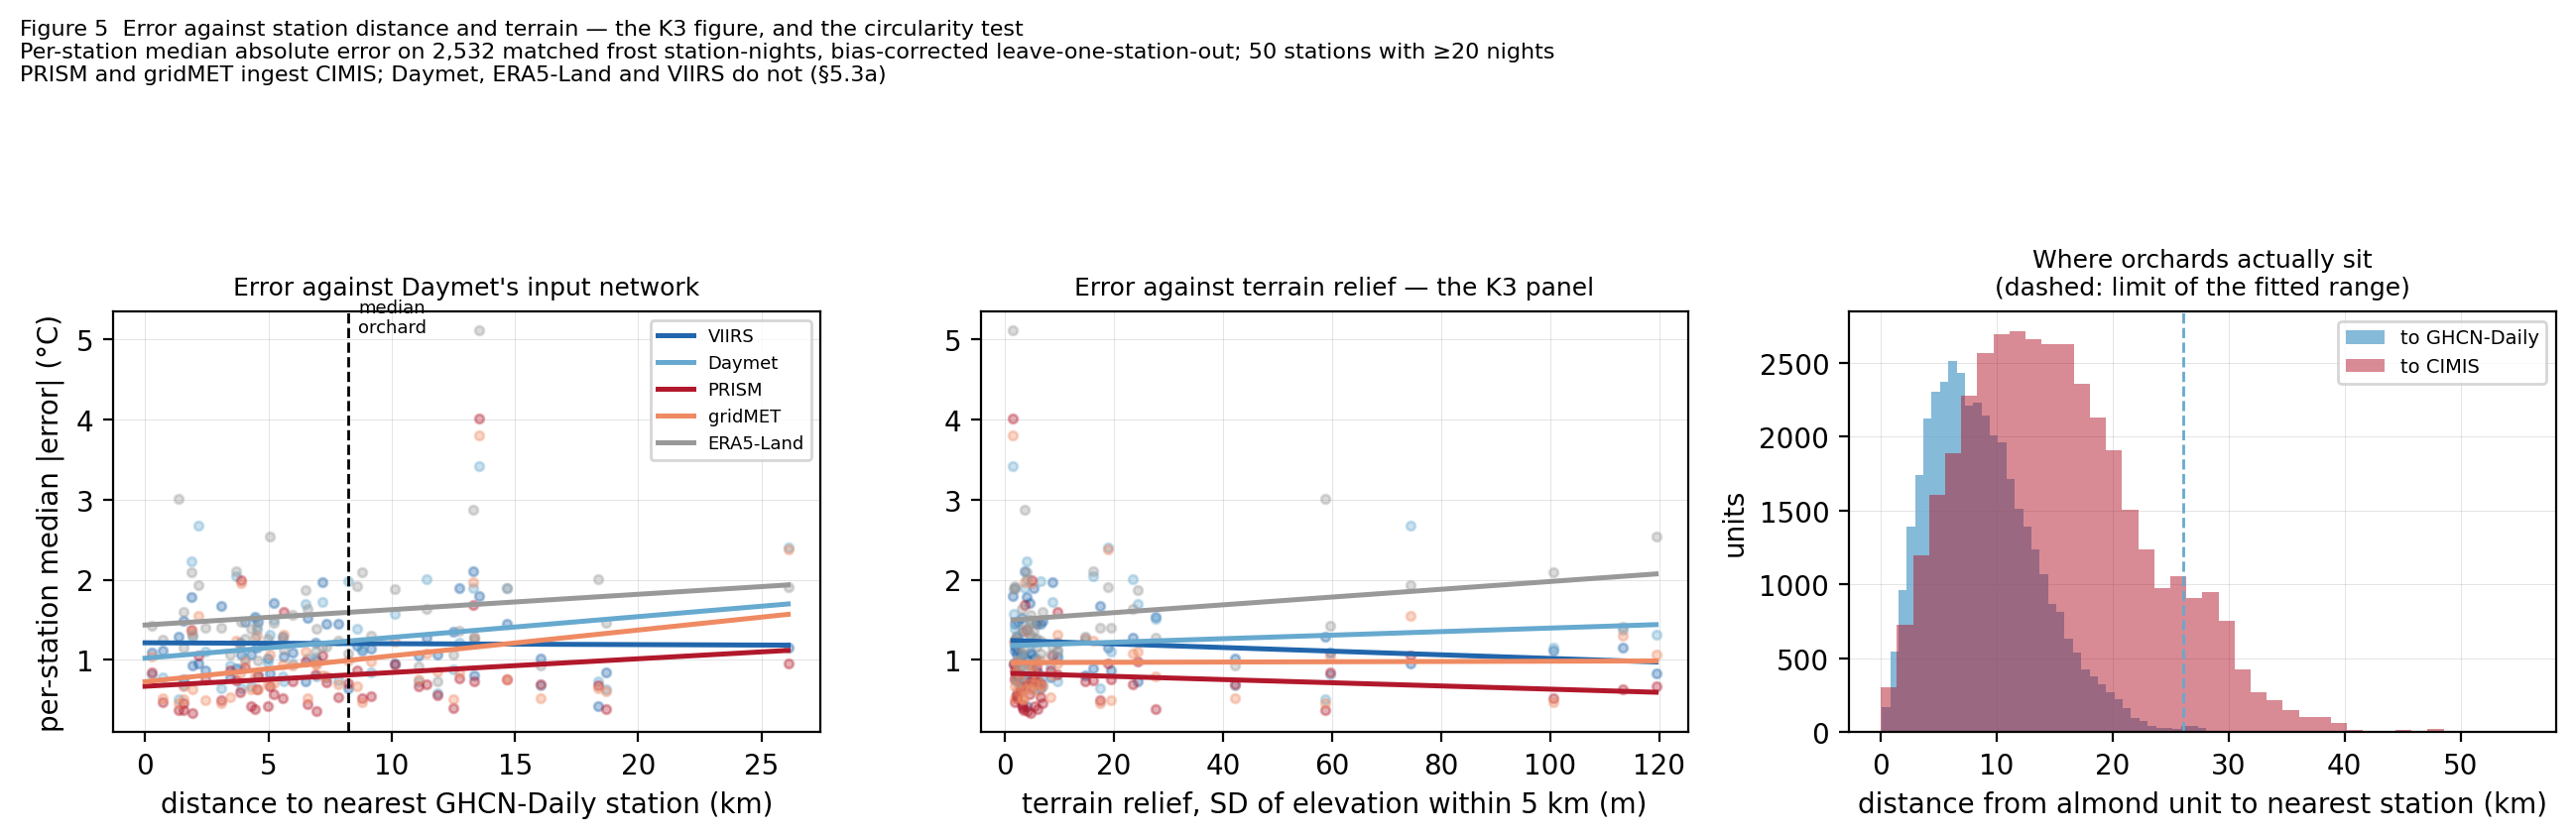

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), dpi=200)
colors = {"VIIRS": "#2166ac", "Daymet": "#67a9cf", "PRISM": "#b2182b", "gridMET": "#ef8a62",
          "ERA5-Land": "#999999"}

ax = axes[0]
for n, _ in PRODS:
    f = fit(n, "d_ghcnd_km")
    xs = np.linspace(0, P.d_ghcnd_km.max(), 50)
    ax.scatter(P.d_ghcnd_km, P[n], s=10, alpha=0.35, color=colors[n])
    ax.plot(xs, f["intercept"] + f["slope"] * xs, color=colors[n], lw=1.8, label=n)
ax.axvline(np.median(d_ghcnd_u), color="k", ls="--", lw=1)
ax.text(np.median(d_ghcnd_u) + 0.4, ax.get_ylim()[1] * 0.95, "median\norchard", fontsize=6.5)
ax.set_xlabel("distance to nearest GHCN-Daily station (km)")
ax.set_ylabel("per-station median |error| (°C)")
ax.set_title("Error against Daymet's input network", fontsize=9)
ax.legend(fontsize=6.5)
ax.grid(lw=0.3, alpha=0.4)
ax.set_axisbelow(True)

ax = axes[1]
for n, _ in PRODS:
    f = fit(n, "relief_sd")
    xs = np.linspace(P.relief_sd.min(), P.relief_sd.max(), 50)
    ax.scatter(P.relief_sd, P[n], s=10, alpha=0.35, color=colors[n])
    ax.plot(xs, f["intercept"] + f["slope"] * xs, color=colors[n], lw=1.8, label=n)
ax.set_xlabel("terrain relief, SD of elevation within 5 km (m)")
ax.set_title("Error against terrain relief — the K3 panel", fontsize=9)
ax.grid(lw=0.3, alpha=0.4)
ax.set_axisbelow(True)

ax = axes[2]
ax.hist(d_ghcnd_u, bins=40, color="#67a9cf", alpha=0.8, label="to GHCN-Daily")
ax.hist(d_cimis_u, bins=40, color="#b2182b", alpha=0.5, label="to CIMIS")
ax.axvline(P.d_ghcnd_km.max(), color="#67a9cf", ls="--", lw=1)
ax.set_xlabel("distance from almond unit to nearest station (km)")
ax.set_ylabel("units")
ax.set_title("Where orchards actually sit\n(dashed: limit of the fitted range)", fontsize=9)
ax.legend(fontsize=7)
ax.grid(lw=0.3, alpha=0.4)
ax.set_axisbelow(True)

fig.suptitle("Figure 5  Error against station distance and terrain — the K3 figure, and the "
             "circularity test\n"
             f"Per-station median absolute error on {len(matched):,} matched frost "
             f"station-nights, bias-corrected leave-one-station-out; "
             f"{len(P)} stations with ≥{MIN_NIGHTS} nights\n"
             "PRISM and gridMET ingest CIMIS; Daymet, ERA5-Land and VIIRS do not (§5.3a)",
             fontsize=8, x=0.005, y=0.995, ha="left", va="top")
fig.tight_layout(rect=(0, 0, 1, 0.87))
fig.savefig(C.FIGURES / "fig05_distance_terrain.png", dpi=200, bbox_inches="tight")
print(f"Figure 5: {len(P)} stations, {len(matched):,} matched station-nights")
print("saved figures/fig05_distance_terrain.png")

In [7]:
P.to_csv(C.DERIVED / "05_station_errors.csv", index=False)
dist_tbl.to_csv(C.DERIVED / "05_distance_slopes.csv", index=False)
cross_tbl.to_csv(C.DERIVED / "05_crossover.csv", index=False)
terr_tbl.to_csv(C.DERIVED / "05_terrain_slopes.csv", index=False)

print("=" * 78)
print("STEP 5 CHECKPOINT SUMMARY — every figure with its denominator")
print("=" * 78)
print(f"matched frost station-nights                  {len(matched):>8,}")
print(f"stations with >= {MIN_NIGHTS} of them              {len(P):>8}   of "
      f"{matched.station.nunique()}")
print(f"slopes distinguishable from zero (distance)   {'none':>8}")
print(f"slopes distinguishable from zero (relief)     {'VIIRS only':>8}")
print(f"Daymet fitted line meets VIIRS at            "
      f"{cross_tbl[cross_tbl['product'] == 'Daymet'].crossover_km.iloc[0]:>8} km")
print(f"median almond unit to nearest GHCN-D station  {np.median(d_ghcnd_u):>8.1f} km")
print(f"median almond unit to nearest CIMIS station   {np.median(d_cimis_u):>8.1f} km")
print(f"K3                                            {'NOT ESTABLISHED':>8}")
print(f"circularity test                              {'INCONCLUSIVE':>8}")
print("\nwrote data/derived/: 05_station_errors.csv, 05_distance_slopes.csv, 05_crossover.csv,")
print("      05_terrain_slopes.csv; figures/fig05_distance_terrain.png")

STEP 5 CHECKPOINT SUMMARY — every figure with its denominator
matched frost station-nights                     2,532
stations with >= 20 of them                    50   of 59
slopes distinguishable from zero (distance)       none
slopes distinguishable from zero (relief)     VIIRS only
Daymet fitted line meets VIIRS at                 7.1 km
median almond unit to nearest GHCN-D station       8.2 km
median almond unit to nearest CIMIS station       14.4 km
K3                                            NOT ESTABLISHED
circularity test                              INCONCLUSIVE

wrote data/derived/: 05_station_errors.csv, 05_distance_slopes.csv, 05_crossover.csv,
      05_terrain_slopes.csv; figures/fig05_distance_terrain.png
